## The Concrete Dataset

For our deep learning journey, we will work with a real-world dataset:  
**Concrete Compressive Strength** dataset.

🔹 **What's inside this dataset?**
- **8 input features** related to the material composition and age of concrete:
  - Cement, Blast Furnace Slag, Fly Ash, Water, Superplasticizer, Coarse Aggregate, Fine Aggregate, and Age (days).
- **1 output feature** (target):
  - Concrete Compressive Strength (in Megapascals, MPa).

---

🔵 **Why is this dataset important?**

- Concrete is the **most important construction material** in civil engineering.
- The strength of concrete depends on **complex, nonlinear relationships** between ingredients and curing time.
- Predicting compressive strength accurately helps in **designing stronger, safer structures**.

---

✅ **Goal:**  
Learn how to load, inspect, and work with real-world tabular data in preparation for building predictive models!

---
**Reference:**  
- [UCI Machine Learning Repository - Concrete Data Set](https://archive.ics.uci.edu/dataset/165/concrete+compressive+strength)


In [17]:
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler

## Data Exploration and Visualization

In [10]:
data = pd.read_csv("Concrete_Data.csv")
data.head()

,Cement (component 1)(kg in a m^3 mixture),Blast Furnace Slag (component 2)(kg in a m^3 mixture),Fly Ash (component 3)(kg in a m^3 mixture),Water (component 4)(kg in a m^3 mixture),Superplasticizer (component 5)(kg in a m^3 mixture),Coarse Aggregate (component 6)(kg in a m^3 mixture),Fine Aggregate (component 7)(kg in a m^3 mixture),Age (day),"Concrete compressive strength(MPa, megapascals)"
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.99
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.89
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.27
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.05
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.30


In [11]:
print(data.isnull().sum())

Cement (component 1)(kg in a m^3 mixture)                0
Blast Furnace Slag (component 2)(kg in a m^3 mixture)    0
Fly Ash (component 3)(kg in a m^3 mixture)               0
Water  (component 4)(kg in a m^3 mixture)                0
Superplasticizer (component 5)(kg in a m^3 mixture)      0
Coarse Aggregate  (component 6)(kg in a m^3 mixture)     0
Fine Aggregate (component 7)(kg in a m^3 mixture)        0
Age (day)                                                0
Concrete compressive strength(MPa, megapascals)          0
dtype: int64


In [12]:
inputs = data.iloc[:, :-1]

# Targets: only the last column
targets = data.iloc[:, -1]

In [13]:
# Convert inputs and targets to PyTorch tensors
inputs_tensor = torch.tensor(inputs.values, dtype=torch.float32)
targets_tensor = torch.tensor(targets.values, dtype=torch.float32)

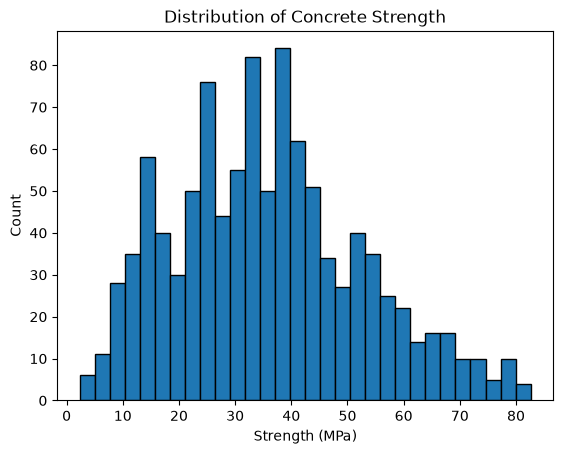

In [14]:
# Plot histogram for the target variable (Concrete Strength)
plt.hist(targets, bins=30, edgecolor='k')
plt.title('Distribution of Concrete Strength')
plt.xlabel('Strength (MPa)')
plt.ylabel('Count')
plt.show()

Text(0.5, 0, 'kg in a $m^3$ mixture')

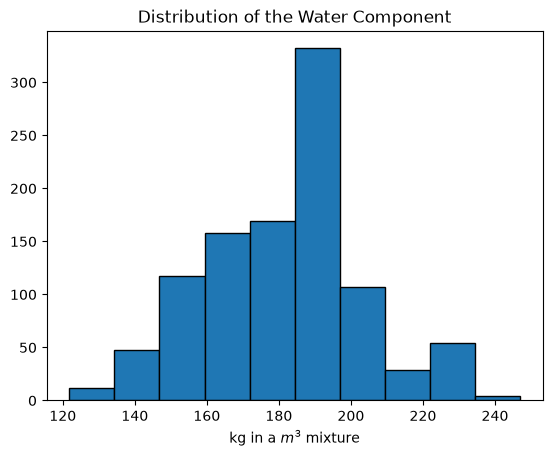

In [15]:
water_feature = inputs['Water  (component 4)(kg in a m^3 mixture)']

# Plot the histogram
plt.hist(water_feature,bins=10,edgecolor='k')
plt.title("Distribution of the Water Component")
plt.xlabel("kg in a $m^3$ mixture")

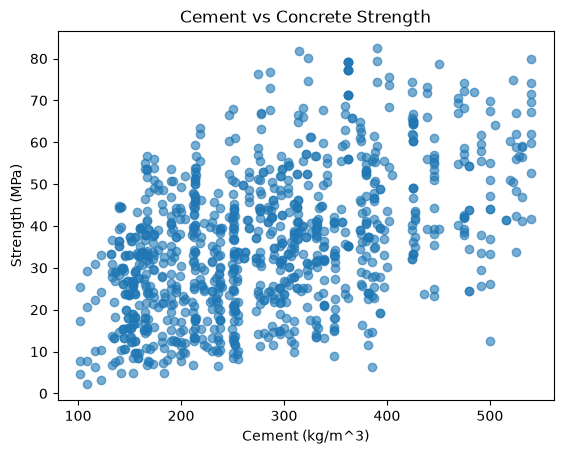

In [16]:
# Scatterplot: Cement vs Concrete Strength
plt.scatter(inputs['Cement (component 1)(kg in a m^3 mixture)'], targets, alpha=0.6)
plt.title('Cement vs Concrete Strength')
plt.xlabel('Cement (kg/m^3)')
plt.ylabel('Strength (MPa)')
plt.show()

## Data Prepareration

In [21]:
scaler = StandardScaler()
inputs_scaled = scaler.fit_transform(inputs)

inputs_tensor = torch.tensor(inputs_scaled, dtype=torch.float32)
targets_tensor = torch.tensor(targets, dtype=torch.float32)

In [49]:
torch.manual_seed(42)
n_samples = inputs_tensor.shape[0]
indices = torch.randperm(n_samples)
split_idx = int(n_samples * 0.8)

train_indices = indices[:split_idx]
test_indices = indices[split_idx:]

X_train = inputs_tensor[train_indices]
y_train = targets_tensor[train_indices]
X_test = inputs_tensor[test_indices]
y_test = targets_tensor[test_indices]

## Building the Neural Network: With a Linear Activation Function

$\hat {\mathbf{y}}=\mathbf{X}\mathbf{W}+\mathbf{b}$

$\mathbf{W}$ is the matrix of the weights

$\mathbf{b}$ is the bais

In [63]:
# Initial parameters
torch.manual_seed(42)
num_features = X_train.shape[1] 
W = torch.randn((num_features, 1), requires_grad=True)
W.data *= 0.01 
b = torch.zeros((1,), requires_grad=True)

In [64]:
# Step 3: Define the predict function
def predict(X):
    return torch.matmul(X,W)+b

# Step 4: Compute predictions
y_train_pred = predict(X_train)

Calculating the Mean Square Error

In [65]:
def mse_loss(predictions, targets):
    return torch.mean((predictions - targets) ** 2)

loss = mse_loss(y_train_pred, y_train)

In the next step we add Gradient Descent so that the can Model learn parameters that minimises the MSE

In [66]:
learning_rate = 0.001
iterations = 100

# Training loop
for ite in range(iterations):
    # 1. Forward pass: compute predictions
    y_train_pred = predict(X_train)
    
    # 2. Compute loss
    loss = mse_loss(y_train_pred, y_train)
    
    # 3. Backward pass: compute gradients
    loss.backward()

    # 4. Update parameters
    with torch.no_grad():
        W -= learning_rate * W.grad
        b -= learning_rate * b.grad

    # 5. Zero gradients
    W.grad.zero_()
    b.grad.zero_()

    # Print loss every 10 epochs
    if (ite + 1) % 10 == 0:
        print(f"Iteration {ite+1}: Loss = {loss.item():.4f}")


Iteration 10: Loss = 1530.0834
Iteration 20: Loss = 1481.1182
Iteration 30: Loss = 1434.0779
Iteration 40: Loss = 1388.8862
Iteration 50: Loss = 1345.4711
Iteration 60: Loss = 1303.7620
Iteration 70: Loss = 1263.6921
Iteration 80: Loss = 1225.1970
Iteration 90: Loss = 1188.2144
Iteration 100: Loss = 1152.6851


Epoch 50: Loss = 994.9130
Epoch 100: Loss = 865.7902
Epoch 150: Loss = 760.1101
Epoch 200: Loss = 673.6135
Epoch 250: Loss = 602.8161
Epoch 300: Loss = 544.8665
Epoch 350: Loss = 497.4318
Epoch 400: Loss = 458.6033
Epoch 450: Loss = 426.8185
Epoch 500: Loss = 400.7991


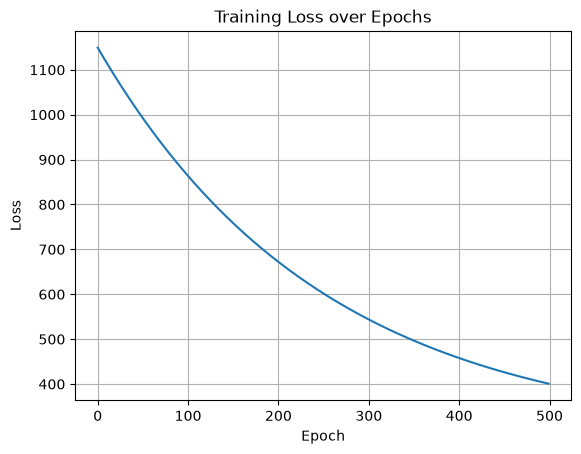

In [67]:
losses = []

# Training loop
learning_rate = 0.001
iterations = 500

for ite in range(iterations):
    y_pred = predict(X_train)
    loss = mse_loss(y_pred, y_train)
    losses.append(loss.item())  # Track the loss

    loss.backward()

    with torch.no_grad():
        W -= learning_rate * W.grad
        b -= learning_rate * b.grad

    W.grad.zero_()
    b.grad.zero_()

    if (ite + 1) % 50 == 0:
        print(f"Iteration {ite+1}: Loss = {loss.item():.4f}")

# Plot loss curve
plt.plot(losses)
plt.xlabel("Iteration")
plt.ylabel("Loss")
plt.title("Training Loss over Iterations")
plt.grid(True)
plt.show()

Evaluating the model on the test data

In [70]:
with torch.no_grad():
    y_test_pred=predict(X_test)
    test_loss = mse_loss(y_test_pred, y_test)